In [1]:
!pip install -q ultralytics opencv-python matplotlib pandas

In [2]:

from google.colab import files
import os

print("Selecione o arquivo best(2).pt")

arquivos = files.upload()

CAMINHO_MODELO = "/content/best(2).pt"

if os.path.exists(CAMINHO_MODELO):
    print("\nModelo enviado com sucesso!")
    print("Arquivo:", CAMINHO_MODELO)
else:
    print("\nVerifique se o arquivo enviado se chama best(2).pt")


Selecione o arquivo best(2).pt


Saving best(2).pt to best(2).pt

Modelo enviado com sucesso!
Arquivo: /content/best(2).pt


In [3]:

import torch
import ultralytics
from ultralytics import YOLO

print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)
print("GPU disponível:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    DISPOSITIVO = 0
else:
    DISPOSITIVO = "cpu"

model = YOLO(CAMINHO_MODELO)

print("\nMODELO CARREGADO!")
print("Classes:", model.names)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics: 8.4.215
PyTorch: 2.14.1+cu130
GPU disponível: True
GPU: Tesla T4

MODELO CARREGADO!
Classes: {0: 'Bus', 1: 'Person', 2: 'walking-frame', 3: 'wheelchair', 4: 'wheelchairs'}


Envie uma imagem para testar o modelo.


Saving 8848_October_2022_in_Białystok.jpg to 8848_October_2022_in_Białystok.jpg


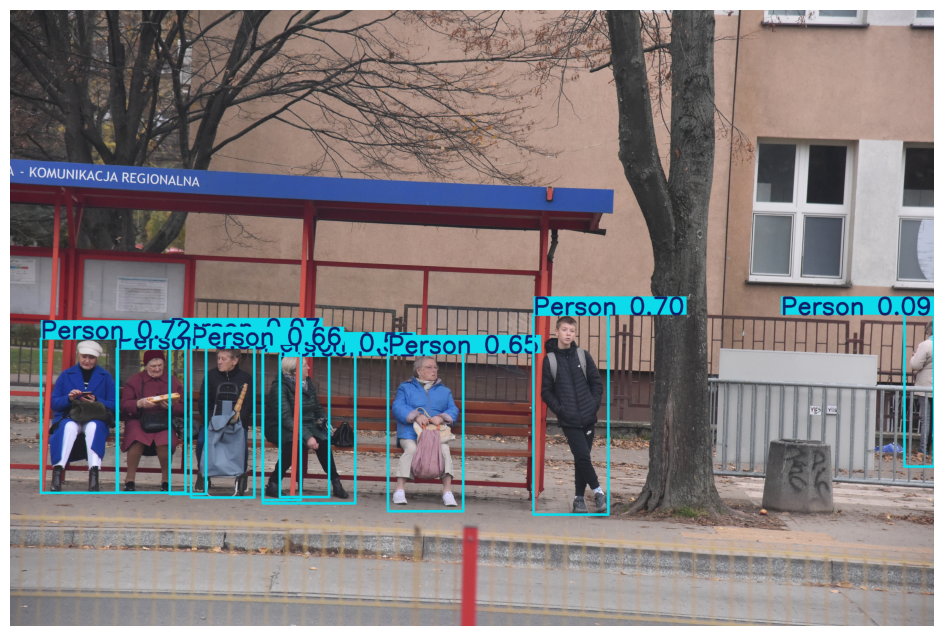


DETECÇÕES
Person | Confiança: 0.718
Person | Confiança: 0.699
Person | Confiança: 0.657
Person | Confiança: 0.649
Person | Confiança: 0.578
Person | Confiança: 0.565
Person | Confiança: 0.395
Person | Confiança: 0.215
Person | Confiança: 0.085
Person | Confiança: 0.071


In [8]:

from google.colab import files
from IPython.display import display
from PIL import Image
import matplotlib.pyplot as plt

print("Envie uma imagem para testar o modelo.")

imagem_enviada = files.upload()
CAMINHO_IMAGEM = "/content/" + list(imagem_enviada.keys())[0]

resultado = model.predict(
    source=CAMINHO_IMAGEM,
    conf=0.05,
    imgsz=640,
    device=DISPOSITIVO,
    verbose=False
)[0]

imagem_resultado = resultado.plot()

plt.figure(figsize=(14, 8))
plt.imshow(imagem_resultado[:, :, ::-1])
plt.axis("off")
plt.show()

print("\nDETECÇÕES")

if resultado.boxes is not None:
    for caixa in resultado.boxes:
        classe_id = int(caixa.cls[0])
        confianca = float(caixa.conf[0])

        print(
            model.names[classe_id],
            "| Confiança:",
            round(confianca, 3)
        )


In [5]:

print("Envie um vídeo para testar.")

video_enviado = files.upload()
VIDEO = "/content/" + list(video_enviado.keys())[0]

print("\nVídeo carregado:", VIDEO)


Envie um vídeo para testar.


Saving 16606194_1920_1080_60fps.mp4 to 16606194_1920_1080_60fps.mp4

Vídeo carregado: /content/16606194_1920_1080_60fps.mp4


In [6]:

import cv2
import pandas as pd
from tqdm.auto import tqdm
import os

PASTA_RESULTADOS = "/content/BusLight_teste_modelo"
os.makedirs(PASTA_RESULTADOS, exist_ok=True)

SAIDA_VIDEO = os.path.join(
    PASTA_RESULTADOS,
    "teste_best2.mp4"
)

SAIDA_CSV = os.path.join(
    PASTA_RESULTADOS,
    "contagem_best2.csv"
)

cap = cv2.VideoCapture(VIDEO)

fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

largura = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
altura = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

cap.release()

print("Total de frames:", total_frames)
print("FPS:", fps)
print("Resolução:", largura, "x", altura)

resultados = model.predict(
    source=VIDEO,
    conf=0.05,
    imgsz=640,
    device=DISPOSITIVO,
    stream=True,
    verbose=False
)

writer = None
dados = []

for numero_frame, resultado in enumerate(
    tqdm(resultados, total=total_frames)
):
    contagem = {
        nome: 0 for nome in model.names.values()
    }

    if resultado.boxes is not None:
        for caixa in resultado.boxes:
            classe_id = int(caixa.cls[0])
            nome_classe = model.names[classe_id]
            contagem[nome_classe] += 1

    dados.append({
        "frame": numero_frame,
        "tempo_s": round(numero_frame / fps, 3) if fps > 0 else 0,
        **contagem,
        "total": sum(contagem.values())
    })

    frame = resultado.plot()

    if writer is None:
        writer = cv2.VideoWriter(
            SAIDA_VIDEO,
            cv2.VideoWriter_fourcc(*"mp4v"),
            fps,
            (frame.shape[1], frame.shape[0])
        )

    writer.write(frame)

if writer is not None:
    writer.release()

df = pd.DataFrame(dados)
df.to_csv(SAIDA_CSV, index=False)

print("\nTESTE CONCLUÍDO!")
print("Frames processados:", len(df))
print("Total de detecções:", df["total"].sum())
print("Vídeo:", SAIDA_VIDEO)
print("Tabela:", SAIDA_CSV)


Total de frames: 957
FPS: 59.94005994005994
Resolução: 1920 x 1080


  0%|          | 0/957 [00:00<?, ?it/s]


TESTE CONCLUÍDO!
Frames processados: 957
Total de detecções: 5530
Vídeo: /content/BusLight_teste_modelo/teste_best2.mp4
Tabela: /content/BusLight_teste_modelo/contagem_best2.csv


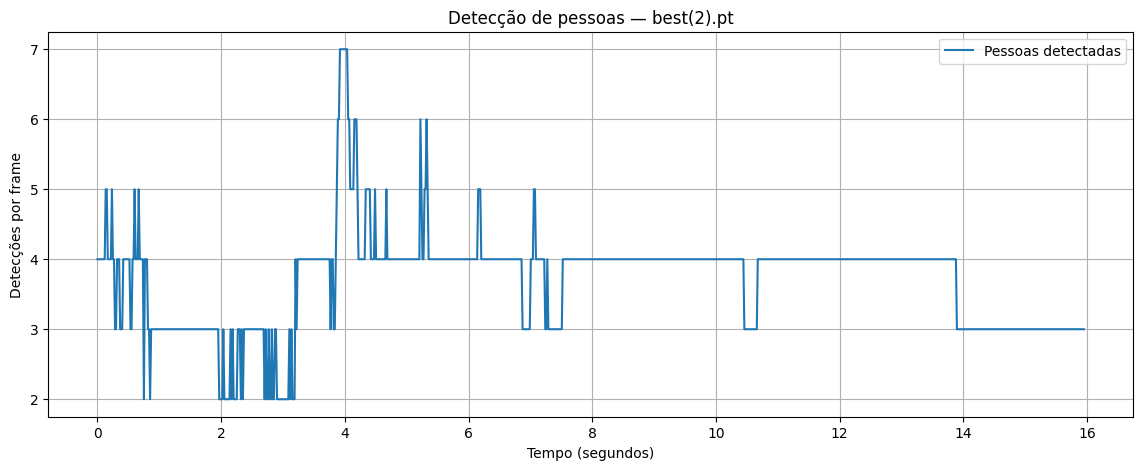

Total de detecções por classe:


,Total
Bus,1034
Person,3539
walking-frame,0
wheelchair,0
wheelchairs,957



Primeiras linhas da tabela:


,frame,tempo_s,Bus,Person,walking-frame,wheelchair,wheelchairs,total
0,0,0.000,1,4,0,0,1,6
1,1,0.017,1,4,0,0,1,6
2,2,0.033,1,4,0,0,1,6
3,3,0.050,2,4,0,0,1,7
4,4,0.067,1,4,0,0,1,6
5,5,0.083,1,4,0,0,1,6
6,6,0.100,1,4,0,0,1,6
7,7,0.117,1,4,0,0,1,6
8,8,0.133,1,5,0,0,1,7
9,9,0.150,1,5,0,0,1,7


In [7]:

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    df["tempo_s"],
    df["Person"],
    label="Pessoas detectadas"
)

plt.xlabel("Tempo (segundos)")
plt.ylabel("Detecções por frame")
plt.title("Detecção de pessoas — best(2).pt")
plt.legend()
plt.grid()
plt.show()

print("Total de detecções por classe:")

display(
    df[list(model.names.values())].sum()
    .rename("Total")
    .to_frame()
)

print("\nPrimeiras linhas da tabela:")
display(df.head(10))


In [9]:

!pip install -q gradio

import gradio as gr
import pandas as pd
from PIL import Image
from collections import Counter

def detectar_imagem(imagem, confianca):
    if imagem is None:
        return None, None, "Envie uma imagem para começar."

    # Executar detecção
    resultado = model.predict(
        source=imagem,
        conf=confianca,
        imgsz=640,
        device=DISPOSITIVO,
        verbose=False
    )[0]

    # Imagem com caixas de detecção
    imagem_detectada = resultado.plot()
    imagem_detectada = imagem_detectada[:, :, ::-1]

    # Registrar detecções
    deteccoes = []

    if resultado.boxes is not None:
        for caixa in resultado.boxes:
            classe_id = int(caixa.cls[0])
            nome = model.names[classe_id]
            score = float(caixa.conf[0])

            x1, y1, x2, y2 = caixa.xyxy[0].cpu().tolist()

            deteccoes.append({
                "Classe": nome,
                "Confiança": f"{score * 100:.2f}%",
                "X1": round(x1, 1),
                "Y1": round(y1, 1),
                "X2": round(x2, 1),
                "Y2": round(y2, 1)
            })

    if deteccoes:
        tabela = pd.DataFrame(deteccoes)

        resumo = Counter(
            item["Classe"] for item in deteccoes
        )

        texto = "Detecção concluída!\n\n"
        texto += f"Total de objetos: {len(deteccoes)}\n\n"

        for classe, quantidade in resumo.items():
            texto += f"{classe}: {quantidade}\n"

    else:
        tabela = pd.DataFrame(
            columns=["Classe", "Confiança", "X1", "Y1", "X2", "Y2"]
        )
        texto = "Nenhum objeto foi detectado nesta imagem."

    return imagem_detectada, tabela, texto


# Criar interface
with gr.Blocks(title="BusLight - Detecção") as interface:

    gr.Markdown(
        """
        # BusLight — Detecção de objetos

        Carregue uma imagem para identificar ônibus, pessoas e
        recursos de mobilidade utilizando o modelo YOLO11.
        """
    )

    with gr.Row():
        with gr.Column():
            entrada = gr.Image(
                label="Carregar imagem",
                type="pil"
            )

            confianca = gr.Slider(
                minimum=0.01,
                maximum=0.90,
                value=0.05,
                step=0.01,
                label="Nível mínimo de confiança"
            )

            botao = gr.Button(
                "Detectar objetos",
                variant="primary"
            )

        with gr.Column():
            saida_imagem = gr.Image(
                label="Resultado da detecção"
            )

    saida_resumo = gr.Textbox(
        label="Resumo das detecções",
        lines=7
    )

    saida_tabela = gr.Dataframe(
        label="Detalhamento dos objetos detectados",
        interactive=False
    )

    botao.click(
        fn=detectar_imagem,
        inputs=[entrada, confianca],
        outputs=[saida_imagem, saida_tabela, saida_resumo]
    )

interface.launch(share=True, debug=True)


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://d02ab17e71ea080bbc.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://d02ab17e71ea080bbc.gradio.live
